In [1]:
import pandas as pd

df = pd.read_excel(
    "/content/HR_Analytics_Dashboard.xlsx",
    sheet_name="Employee_Data"
)

print(df.head())
print("Dataset shape:", df.shape)

  Employee_ID Department                        Job_Role Experience_Category  \
0      EMP001         HR                    HR Executive           0-2 years   
1      EMP002      Sales  Business Development Executive           0-2 years   
2      EMP003    Finance                 Finance Analyst          6-10 years   
3      EMP004      Sales  Business Development Executive           0-2 years   
4      EMP005         IT                      QA Analyst           0-2 years   

  Employment_Type Employee_Status Training_Attended  Working_Days  \
0       Full-time          Active               Yes            22   
1       Full-time          Active                No            22   
2       Full-time          Exited                No            22   
3        Contract          Exited                No            22   
4       Full-time          Active               Yes            22   

   Absent_Days  Performance_Category  
0            0    Meets Expectations  
1            0  Exceeds Ex

In [2]:
#Calculate workforce metrics


total_employees = len(df)

active_employees = (df["Employee_Status"] == "Active").sum()

exited_employees = (df["Employee_Status"] == "Exited").sum()

training_participation = (
    (df["Training_Attended"] == "Yes").sum()
    / total_employees
) * 100

print("Total Employees:", total_employees)
print("Active Employees:", active_employees)
print("Exited Employees:", exited_employees)
print("Training Participation:", round(training_participation, 2), "%")


Total Employees: 50
Active Employees: 42
Exited Employees: 8
Training Participation: 68.0 %


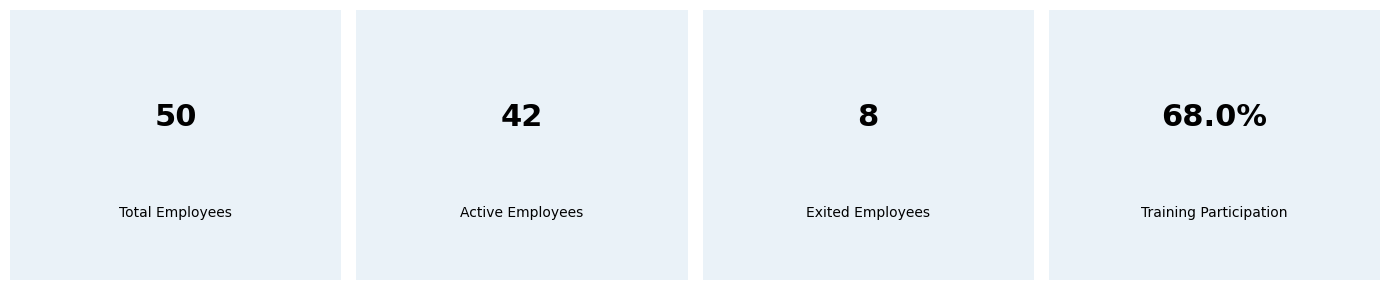

In [8]:
#Create attractive HR dashboard summary cards


import matplotlib.pyplot as plt

metrics = [
    ("Total Employees", total_employees),
    ("Active Employees", active_employees),
    ("Exited Employees", exited_employees),
    ("Training Participation", f"{training_participation:.1f}%")
]

fig, axes = plt.subplots(1, 4, figsize=(14, 3))

for ax, (title, value) in zip(axes, metrics):
    ax.set_facecolor("#EAF2F8")
    ax.text(0.5, 0.6, value, ha="center",
            va="center", fontsize=22, fontweight="bold")
    ax.text(0.5, 0.25, title, ha="center",
            va="center", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

plt.tight_layout()
plt.show()


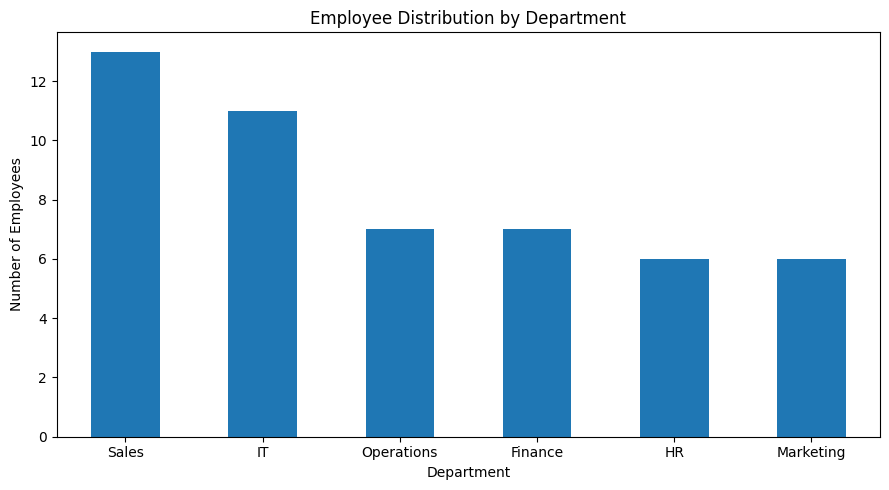

In [9]:
#Create a department-wise employee chart


department_counts = df["Department"].value_counts()

plt.figure(figsize=(9, 5))

department_counts.plot(kind="bar")

plt.title("Employee Distribution by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


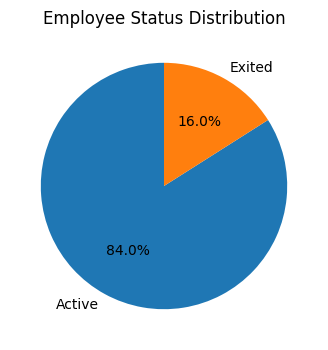

In [10]:
#Create an employee status chart


status_counts = df["Employee_Status"].value_counts()

plt.figure(figsize=(6, 4))

status_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Employee Status Distribution")
plt.ylabel("")
plt.show()


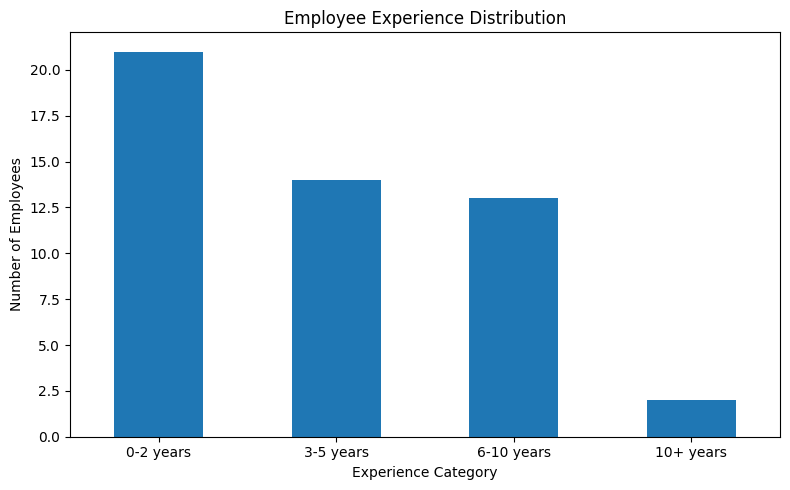

In [11]:
#Create an experience-wise employee chart


experience_counts = df["Experience_Category"].value_counts()

# Keep the experience categories in the correct order
experience_counts = experience_counts.reindex([
    "0-2 years",
    "3-5 years",
    "6-10 years",
    "10+ years"
])

plt.figure(figsize=(8, 5))

experience_counts.plot(kind="bar")

plt.title("Employee Experience Distribution")
plt.xlabel("Experience Category")
plt.ylabel("Number of Employees")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


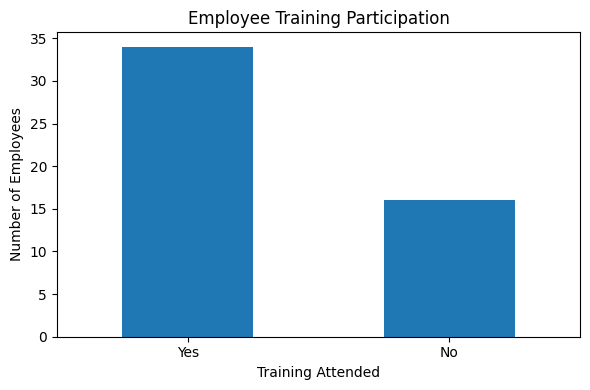

In [12]:
#Create a training participation chart


training_counts = df["Training_Attended"].value_counts()

plt.figure(figsize=(6, 4))

training_counts.plot(
    kind="bar",
    rot=0
)

plt.title("Employee Training Participation")
plt.xlabel("Training Attended")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()


In [13]:
#Add an interactive department filter

import ipywidgets as widgets
from IPython.display import display, clear_output


In [14]:

department_filter = widgets.Dropdown(
    options=["All"] + sorted(df["Department"].unique()),
    value="All",
    description="Department:"
)

output = widgets.Output()

def show_department(change):
    with output:
        clear_output(wait=True)

        if change["new"] == "All":
            filtered_df = df
        else:
            filtered_df = df[
                df["Department"] == change["new"]
            ]

        print("Total Employees:", len(filtered_df))
        print("\nEmployee Status:")
        print(filtered_df["Employee_Status"].value_counts())

        print("\nTraining Participation:")
        print(filtered_df["Training_Attended"].value_counts())

department_filter.observe(show_department, names="value")

display(department_filter, output)

show_department({"new": "All"})


Dropdown(description='Department:', options=('All', 'Finance', 'HR', 'IT', 'Marketing', 'Operations', 'Sales')…

Output()

In [15]:
#Display HR insights and recommendations


# Calculate department-wise training participation
training_by_department = (
    df.groupby("Department")["Training_Attended"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

# Calculate department-wise absenteeism
absence_by_department = (
    df.groupby("Department")
    .apply(lambda x: x["Absent_Days"].sum()
           / x["Working_Days"].sum() * 100)
)

print("HR ANALYTICS – KEY INSIGHTS")
print("---------------------------")

print("1. Largest Department:",
      df["Department"].value_counts().idxmax())

print("2. Smallest Department:",
      df["Department"].value_counts().idxmin())

print("3. Overall Training Participation:",
      round(training_participation, 1), "%")

print("4. Department with Lowest Training:",
      training_by_department.idxmin())

print("5. Department with Highest Absenteeism:",
      absence_by_department.idxmax())


HR ANALYTICS – KEY INSIGHTS
---------------------------
1. Largest Department: Sales
2. Smallest Department: HR
3. Overall Training Participation: 68.0 %
4. Department with Lowest Training: Finance
5. Department with Highest Absenteeism: Sales


/tmp/ipykernel_492/3949227470.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x["Absent_Days"].sum()


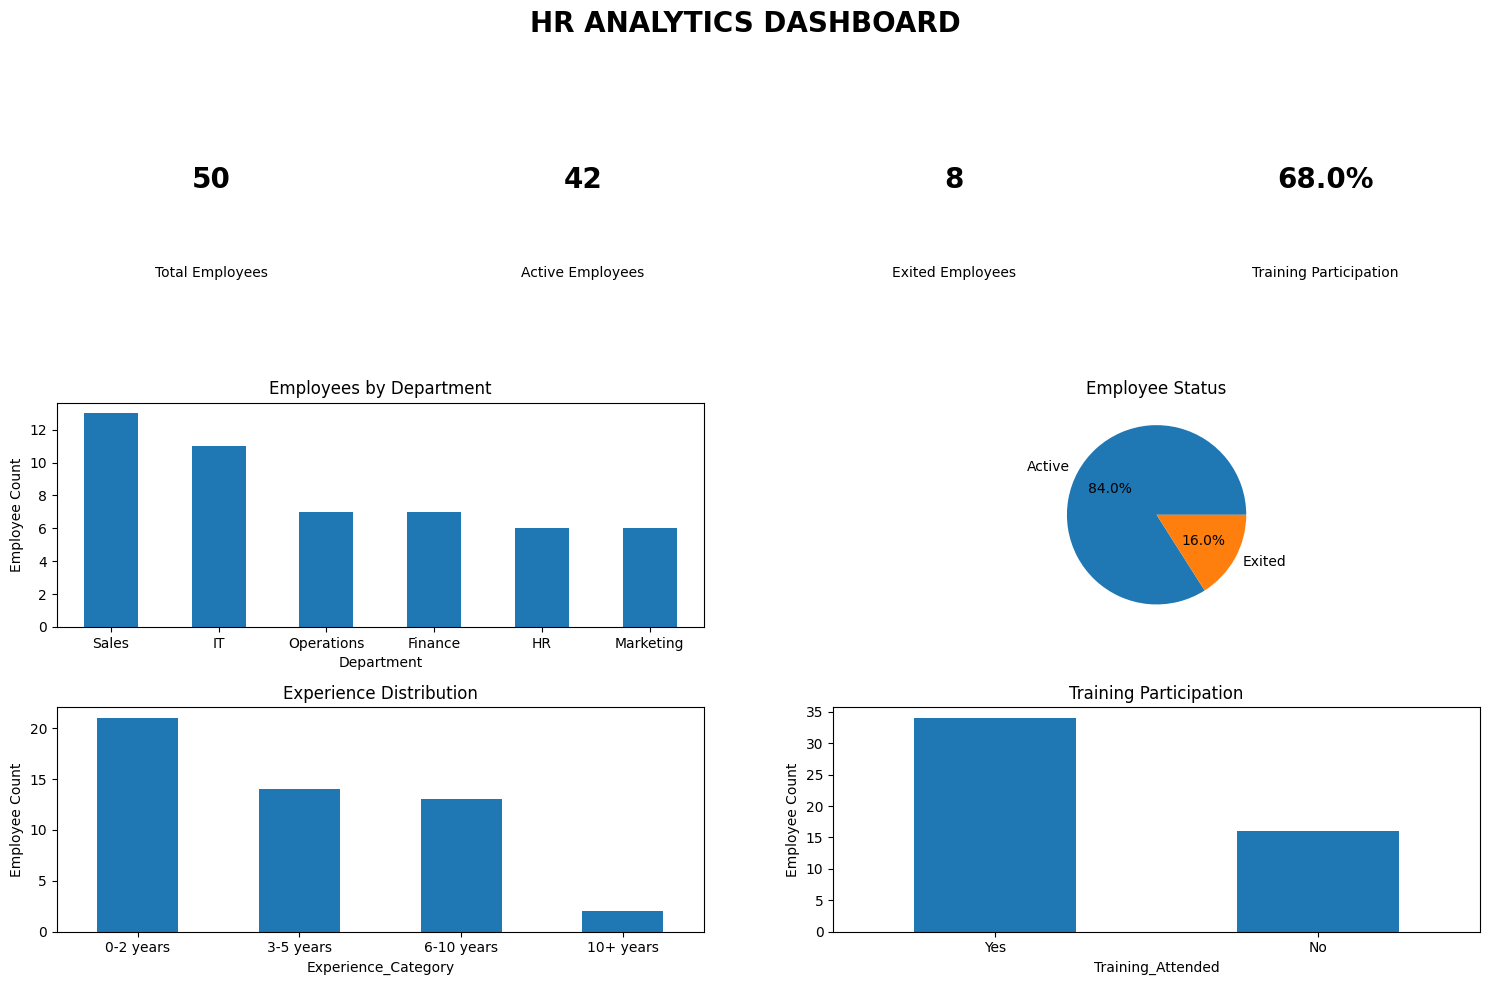

In [16]:
#Create one complete HR dashboard


import matplotlib.pyplot as plt

# Create one dashboard with 3 rows and 2 columns
fig = plt.figure(figsize=(15, 10))
fig.suptitle("HR ANALYTICS DASHBOARD", fontsize=20, fontweight="bold")

# KPI cards at the top
kpis = [
    ("Total Employees", total_employees),
    ("Active Employees", active_employees),
    ("Exited Employees", exited_employees),
    ("Training Participation", f"{training_participation:.1f}%")
]

for i, (label, value) in enumerate(kpis):
    ax = fig.add_subplot(3, 4, i + 1)
    ax.text(0.5, 0.6, value, ha="center", fontsize=20,
            fontweight="bold")
    ax.text(0.5, 0.2, label, ha="center", fontsize=10)
    ax.set_axis_off()

# Department chart
ax1 = fig.add_subplot(3, 2, 3)
df["Department"].value_counts().plot(kind="bar", ax=ax1)
ax1.set_title("Employees by Department")
ax1.set_ylabel("Employee Count")
ax1.tick_params(axis="x", rotation=0)

# Employee status chart
ax2 = fig.add_subplot(3, 2, 4)
df["Employee_Status"].value_counts().plot(kind="pie",
    autopct="%1.1f%%", ax=ax2)
ax2.set_title("Employee Status")
ax2.set_ylabel("")

# Experience chart
ax3 = fig.add_subplot(3, 2, 5)
experience_order = ["0-2 years", "3-5 years", "6-10 years", "10+ years"]
df["Experience_Category"].value_counts().reindex(
    experience_order
).plot(kind="bar", ax=ax3)
ax3.set_title("Experience Distribution")
ax3.set_ylabel("Employee Count")
ax3.tick_params(axis="x", rotation=0)

# Training chart
ax4 = fig.add_subplot(3, 2, 6)
df["Training_Attended"].value_counts().plot(kind="bar", ax=ax4)
ax4.set_title("Training Participation")
ax4.set_ylabel("Employee Count")
ax4.tick_params(axis="x", rotation=0)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


In [17]:
#Download your complete dashboard as an image

# Save the complete dashboard as a PNG image
fig.savefig(
    "HR_Analytics_Dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

# Download the image
from google.colab import files
files.download("HR_Analytics_Dashboard.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>